### 🎓 Module 1: Simple Linear Regression 

In this notebook, we are going to explore **Simple Linear Regression** using the **Ordinary Least Squares (OLS)** method. Machine Learning (ML) industry standards use the following nomenclature:
- $w$ (**weight**): Represents the slope ($\beta_1$). It is the marginal impact of the independent variable on the dependent variable.
- $b$ (**bias**): Represents the Y-intercept ($\beta_0$). It is the expected value of the output when the input is zero.

### Analytical Formulas For Optimizing $y$ = $x$·$w$ + $b$ + $\varepsilon$
The objective of OLS is to minimize the sum of squared errors. The closed-form analytical solutions to optimize the parameters are:
$$w = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2} = \frac{Cov(X,Y)}{Var(X)}$$
$$b = \bar{y} - w\bar{x}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. GENERATE RANDOM DATA

# We fix the size of the data and the seed for reproducibility
STUDENTS = 100
np.random.seed(42)

# We generate the study hours (between 1 and 10 hours) for the 100 students
study_hours = np.random.uniform(1.0, 10.0, STUDENTS)

# We define a Theoretical Linear Relationship (y = x*w + b + noise)
b_theoretical = 2.5
w_theoretical = 0.7
noise = np.random.normal(0, 0.8, STUDENTS)

exam_notes = study_hours * w_theoretical + b_theoretical + noise

# Adjust the limits of the Gauss Distribution (we don't want marks under 0 or over 10)
exam_notes = np.clip(exam_notes, 0.0, 10.0)

# Build the Pandas DataFrame (CVS file dicctionary)
data = {
    'Study Hours': study_hours,
    'Exam Notes': exam_notes
}

df = pd.DataFrame(data)

df.to_csv('students_data.csv', index=False)
print('Data generated successfully!')
df.head()

Data generated successfully!


,Study Hours,Exam Notes
0,4.370861,5.629240
1,9.556429,8.950294
2,7.587945,7.884970
3,6.387926,5.381493
4,2.404168,4.007180


--- STATISTICS OF THE CSV FILE ---
       Study Hours  Exam Notes
count   100.000000  100.000000
mean      5.231627    6.159544
std       2.677405    1.903208
min       1.049699    2.749393
25%       2.738807    4.523211
50%       5.177282    5.838089
75%       7.571828    7.760507
max       9.881982   10.000000


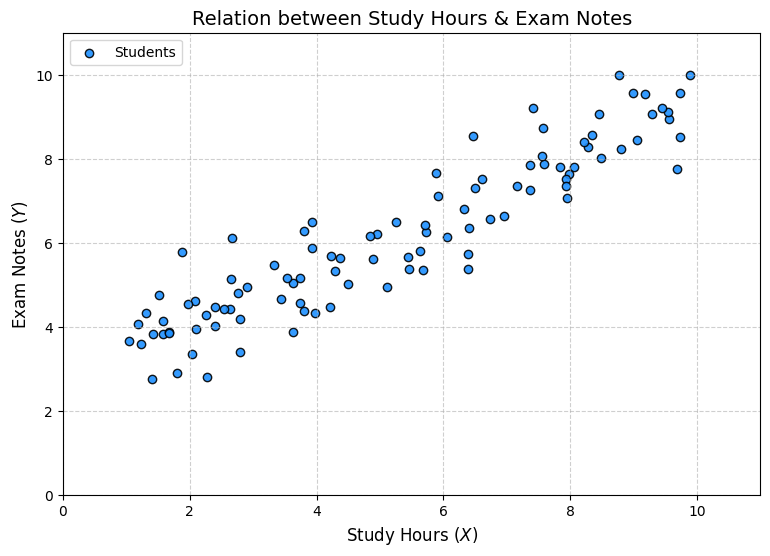

In [2]:
# 2. EXPLORATORY DATA ANALYSIS
# Before running any algorithm, a good engineer analyzes the data distribution. We will use Pandas and Matplotlib

# Open the CVS file and explore it
df = pd.read_csv('students_data.csv')

# Data Statistic Resume (Pandas)
print('--- STATISTICS OF THE CSV FILE ---')
print(df.describe())

# Data Visualization (Matplotlib)
plt.figure(figsize=(9, 6))
plt.scatter(df['Study Hours'], df['Exam Notes'], color='dodgerblue', edgecolors='k', alpha=0.9, label='Students')
plt.title('Relation between Study Hours & Exam Notes', fontsize=14)
plt.xlabel('Study Hours ($X$)', fontsize=12)
plt.ylabel('Exam Notes ($Y$)', fontsize=12)
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)
plt.show()


In [3]:
# 3. IMPLEMENTING ORDINARY LEAST SQUARES 'BY HAND' (OLS)
# We use Numpy vectorization in order to calculate by OLS our parameters b and w

X = df['Study Hours'].to_numpy()
Y = df['Exam Notes'].to_numpy()

X_mean = np.mean(X) 
Y_mean = np.mean(Y)

cov_XY = np.sum((X - X_mean) * (Y - Y_mean))
var_X = np.sum((X - X_mean)**2)

w = (cov_XY / var_X)
b = (Y_mean - w*X_mean)

print('--- OPTIMIZED PARAMETERS b and w by OLS ---')
print(f'Stimated weight: w = {w: .4f} (Original Theoretical: {w_theoretical})')
print(f'Stimated bias: b = {b: .4f} (Original Theoretical: {b_theoretical})')
print(f'Model Ecuation: ŷ = {b:.4f} + {w:.4f} * x')

--- OPTIMIZED PARAMETERS b and w by OLS ---
Stimated weight: w =  0.6582 (Original Theoretical: 0.7)
Stimated bias: b =  2.7161 (Original Theoretical: 2.5)
Model Ecuation: ŷ = 2.7161 + 0.6582 * x


In [4]:
# 4. INFERENCE (PREDICTIONS) & COMPARATION WITH ORIGINAL RESULTS
# Once we calculated b and w we can form the simple lineal regression model prediction
Y_pred = w*X + b

# Add the new column to the DataFrame
df['Predicted Notes'] = Y_pred

# Show the comparative Theoretical vs Prediction
print("--- Comparative DataFrame: Theoretical vs Prediction ---")
df[['Study Hours', 'Exam Notes', 'Predicted Notes']].head(10)

--- Comparative DataFrame: Theoretical vs Prediction ---


,Study Hours,Exam Notes,Predicted Notes
0,4.370861,5.629240,5.592987
1,9.556429,8.950294,9.006137
2,7.587945,7.884970,7.710478
3,6.387926,5.381493,6.920623
4,2.404168,4.007180,4.298505
5,2.403951,4.468456,4.298363
6,1.522753,4.748242,3.718356
7,8.795585,8.242294,8.505348
8,6.410035,6.340230,6.935175
9,7.372653,7.259452,7.568772


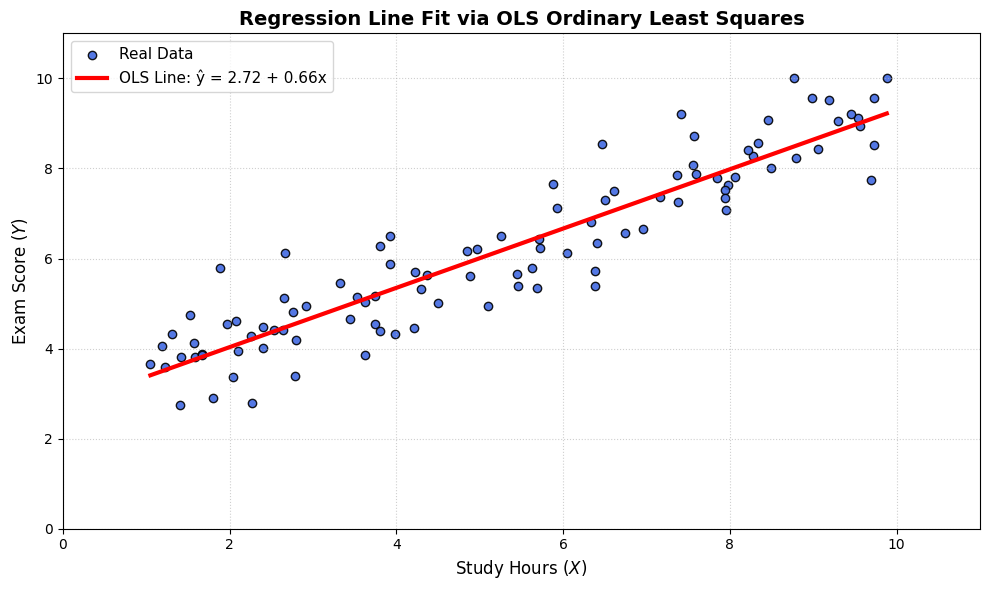

In [5]:
# 5. PLOTTING THE REGRESSION LINE
plt.figure(figsize=(10, 6))

# Dibujamos los puntos reales (Scatter plot)
plt.scatter(df['Study Hours'], df['Exam Notes'], color='royalblue', alpha=0.9, edgecolors='k', label='Real Data')

# Draw the adjusted line by Ordinary Least Square method
# To ensure it looks perfect, we sort X from lowest to highest when plotting the line
X_tidy = np.sort(X)
Y_pred_tidy = X_tidy * w + b 
plt.plot(X_tidy, Y_pred_tidy, color='red', linewidth=3, label=f'OLS Line: ŷ = {b:.2f} + {w:.2f}x')

# Engineering annotations and aesthetics
plt.title('Regression Line Fit via OLS Ordinary Least Squares', fontsize=14, fontweight='bold')
plt.xlabel('Study Hours ($X$)', fontsize=12)
plt.ylabel('Exam Score ($Y$)', fontsize=12)
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()